# QuantumBridge 量子蒙特卡洛与可微金融研究

真实股票历史回放 / Local execution, not hardware

## 真实数据与运行条件 / Real data & reproducibility

输入是 MSFT、IBM、SBUX、AAPL 的真实历史价格序列，不是生成的股票数据。
固定训练窗口为 **2015-01-02 至 2015-12-31（252 个交易日）**；组合验证使用 2016 年的独立留出窗口。
行情来源为 Plotly 公开数据仓库，数据字节以 SHA-256 验证，源提交和许可保存在包内。
原始复权方法未得到独立核验，因此价格、单股成本与损益均为**来源价格口径的历史回放**，不宣称经审计总收益或今天可以买卖的报价。

在本仓库安装 `pip install -e ".[finance-apps]"`，另装 `jupyter nbconvert matplotlib`，选择同一个 Python 内核。
本 Notebook 可在仓库根目录从上到下运行；不自动联网、不读取 token、不提交云任务。
包内数据支持离线重跑，改变参数后得到的是重新计算的模型结果。

所有金额均为 USD。定价是模型估值而非已观测期权成交价；历史风险与未来风险不等价。
读取、统计、分箱和一般状态制备都有经典成本；这里不假设免费 QRAM，也未建立端到端量子加速。

In [1]:
import sys, json, importlib.metadata, html
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from quantumbridge.finance import (
    load_stock_history, build_portfolio_cqm, solve_portfolio,
    pricing_case, risk_case, pennylane_qmc, hybrid_volatility_case,
)
from quantumbridge.finance.gate_exports import measurement_artifact
SHOTS, SEED = 1024, 20261102
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {p: importlib.metadata.version(p) for p in ['numpy','scipy','dimod','pennylane','torch']}
print('Python', sys.version.split()[0], '| installed dependencies:', versions)
print('Hardware jobs: 0 | Frozen historical replay, not current quotes or investment advice')

def table(rows):
    keys = list(rows[0])
    def cell(value):
        return html.escape(f'{value:.6g}' if isinstance(value, (float, np.floating)) else str(value))
    markup = '<div class="qb-table"><table><thead><tr>'+''.join('<th>'+cell(k)+'</th>' for k in keys)+'</tr></thead><tbody>'
    markup += ''.join('<tr>'+''.join('<td>'+cell(row[k])+'</td>' for k in keys)+'</tr>' for row in rows)
    display(HTML(markup+'</tbody></table></div>'))

def clean(value):
    if isinstance(value, dict):
        return {k: clean(v) for k,v in value.items() if k not in ('circuit','circuits','preparation')}
    if isinstance(value, (list,tuple)): return [clean(v) for v in value]
    if isinstance(value, np.generic): return value.item()
    return value

history = load_stock_history()
print(json.dumps(history.provenance, ensure_ascii=False, indent=2))
table([dict(symbol=s, first=history.dates[0], last=history.dates[-1], source_price_usd=float(history.prices[-1,i]))
       for i,s in enumerate(history.symbols)])

Python 3.12.6 | installed dependencies: {'numpy': '2.4.6', 'scipy': '1.18.1', 'dimod': '0.12.22', 'pennylane': '0.44.1', 'torch': '2.12.0'}
Hardware jobs: 0 | Frozen historical replay, not current quotes or investment advice
{
  "provider": "Plotly public datasets / stockdata.csv",
  "source_url": "https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv",
  "download_url": "https://raw.githubusercontent.com/plotly/datasets/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv",
  "source_commit": "0f7c47868a3393316098a8bf97d548e1ee23d22a",
  "sha256": "60bf505fec160ce05ba959382adee32ea6e53ce14fe22886db27c58fe1b0d26b",
  "retrieved_date_utc": "2026-11-01",
  "observations": [
    "2007-01-03",
    "2016-03-01"
  ],
  "symbols": [
    "MSFT",
    "IBM",
    "SBUX",
    "AAPL",
    "GSPC"
  ],
  "currency": "USD",
  "license_url": "https://github.com/plotly/datasets/blob/master/LICENSE",
  "license_file": "PLOTLY_LICENSE.txt",
  "license": "MIT as p

symbol,first,last,source_price_usd
MSFT,2015-01-02,2015-12-31,55.0845
IBM,2015-01-02,2015-12-31,136.228
SBUX,2015-01-02,2015-12-31,59.8345
AAPL,2015-01-02,2015-12-31,104.692


<a id="pricing"></a>
## 1. 量子蒙特卡洛：IBM 欧式期权模型定价

输入是 IBM 2015 年真实价格，S₀ 为来源中 2015-12-31 的价格，σ 由训练期对数收益标准差年化。
示例假设 r=3%、零股息、剩余 30/252 年、K=S₀；这些是明确的模型参数，不是市场期权合约报价。
风险中性 Q 下的 GBM 为 Sᵀ = S₀ exp[(r−σ²/2)T + σ√T z]。
将标准正态等概率分为 8 格，采用各格中点分位数，支付为折现后的 max(Sᵀ−K,0) 或 max(K−Sᵀ,0)。

先把支付仿射归一化到 [0,1]，RY/CX 制备 A|0〉 = Σ√pᵢ |i〉(√(1−fᵢ)|0〉+√fᵢ|1〉)。
末位 1 的概率即 μ=Σpᵢfᵢ。QuantumBridge 运行 A、QA、Q²A、Q⁴A，
对各电路实际计数拟合 sin²[(2k+1)θ] 的二项似然，再反归一化得到金融金额。
不是从经典期望值直接填入“量子结果”。每个电路 1024 shots，共 4096 shots；
Grover 调用总计 7168，A/A† 等价制备调用总计 18432（不等于物理门数）。

比较三个量：连续 Black–Scholes、8 格经典精确期望、本地有限 shots 的 MLAE。
前两者差是模型离散化误差；后两者差才是本次估计误差，不能混在一起。

{'spot': 136.22849, 'strike': 136.22849, 'volatility': 0.2128641404065658, 'rate': 0.03, 'maturity_days': 30, 'dates': ['2015-01-02', '2015-12-31'], 'probability_measure': 'Risk-neutral Q; GBM, zero dividend yield assumed'}


scenario,probability,terminal_price,discounted_call,discounted_put
0,0.125,121.819,0,14.3584
1,0.125,127.747,0,8.45131
2,0.125,131.54,0,4.67195
3,0.125,134.781,0,1.44193
4,0.125,137.932,1.69754,0
5,0.125,141.331,5.08453,0
6,0.125,145.527,9.26577,0
7,0.125,152.609,16.3225,0


payoff,black_scholes,discrete,native_mlae,unamplified,grid_error,estimation_error,likelihood_95_interval
call,4.23107,4.04629,4.05883,4.2719,-0.184781,0.0125362,"[4.007773786244297, 4.1099722643667125]"
put,3.74541,3.61545,3.60551,3.51948,-0.129963,-0.00993496,"[3.5601710708152816, 3.6509270696583482]"


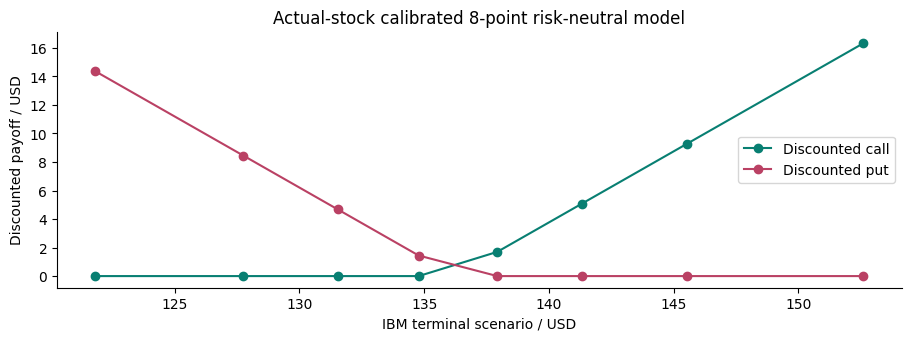

In [2]:
pricing = pricing_case(strike_ratio=1., rate=.03, maturity_days=30, shots=SHOTS, seed=SEED)
print({k:pricing[k] for k in ['spot','strike','volatility','rate','maturity_days','dates','probability_measure']})
table([dict(scenario=i, probability=p, terminal_price=s, discounted_call=c, discounted_put=v)
       for i,(p,s,c,v) in enumerate(zip(pricing['probabilities'],pricing['scenario_prices'],pricing['call_payoffs'],pricing['put_payoffs']))])
table([dict(payoff=k, black_scholes=pricing['black_scholes'][k], discrete=pricing[k]['exact_discrete'],
            native_mlae=pricing[k]['estimate'], unamplified=pricing[k]['unamplified_estimate'],
            grid_error=pricing[k]['exact_discrete']-pricing['black_scholes'][k],
            estimation_error=pricing[k]['estimate']-pricing[k]['exact_discrete'],
            likelihood_95_interval=pricing[k]['confidence_interval']) for k in ['call','put']])
fig, ax = plt.subplots(figsize=(9,3.3), layout='constrained')
ax.plot(pricing['scenario_prices'],pricing['call_payoffs'],'o-',label='Discounted call',color='#087f72')
ax.plot(pricing['scenario_prices'],pricing['put_payoffs'],'o-',label='Discounted put',color='#ba4164')
ax.set(xlabel='IBM terminal scenario / USD',ylabel='Discounted payoff / USD',title='Actual-stock calibrated 8-point risk-neutral model')
ax.legend(); plt.show()

## 2. 实际 PennyLane 参考调用和中间结果

下面真正调用已安装 PennyLane 的 `QuantumMonteCarlo` 模板和 `default.qubit`。
该模板用矩阵实现、不可直接求导，属于模拟器参考路径；不是夸父直接执行入口。
为避免平方反射的 μ 与 1−μ 相位歧义，支付编码到 [0,1/2]，取共轭峰折叠后的模态格点。
保留所有相位概率，5 个估计位加 4 个目标位共 9 比特，显示有限相位分辨率误差。
这与只需 4 比特的 Native MLAE 是两条不同实现路径，不把参考模板冒充原生完整替代。

{'backend': 'PennyLane.default.qubit / QuantumMonteCarlo', 'version': '0.44.1', 'estimate': 3.7050330586557436, 'phase': 0.21875, 'qubits': 9, 'estimation_wires': 5, 'exact_discrete': 4.046290235543493, 'hardware_jobs': 0, 'grid_amplitude': 0.1134947733186315, 'normalization': {'offset': 0.0, 'scale': 32.64496637439002, 'range': '[0, 1/2] to avoid reflection phase alias'}}


power,counts,successes,success_rate
0,"{'0': 756, '1': 268}",268,0.261719
1,{'1': 1024},1024,1
2,"{'1': 278, '0': 746}",278,0.271484
4,{'1': 1024},1024,1


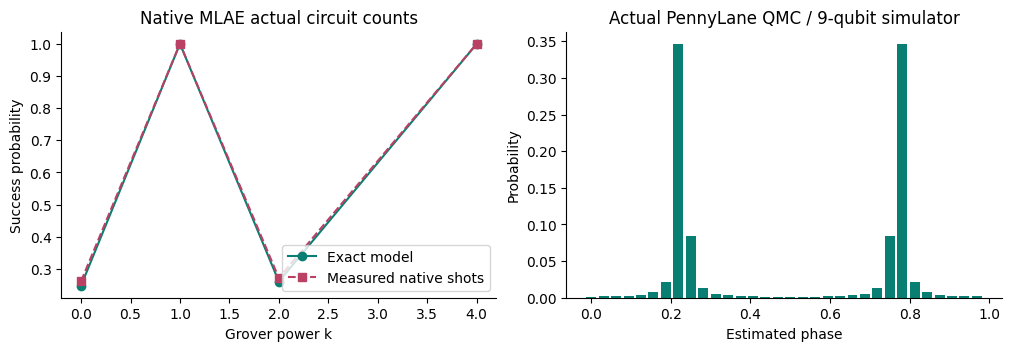

power,qubits,gates,two_qubit_gates,sha256
0,4,35,24,31b3bc5dd41fe450fe6f53683c3210452ad0b9b1d3cf043e3772041b768383dc
1,4,155,106,d8859ca7252a3b4dcd865dced86cfaa13d0bf67cbac2242237c1b2eb4ddaa54c
2,4,275,188,66261114513b1eb82d1ccb1e5b0b20e17e45acb63f46e38a2d30c2edbee591c5
4,4,515,352,87e5d4ee40c29b031f73f8f8312e0db10f2fb4749c73c787ed6b4d054a7d0e46


Native A / preparation circuit QASM2:
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
ry(1.5707963267948966) q[0];
ry(1.5707963267948966) q[1];
ry(1.5707963267948966) q[2];
ry(0.83613924177580945) q[3];
cx q[2],q[3];
ry(-0.24532159515415741) q[3];
cx q[2],q[3];
cx q[1],q[3];
ry(-0.37589671088358145) q[3];
cx q[1],q[3];
cx q[1],q[3];
cx q[2],q[3];
ry(0.11343877898134817) q[3];
cx q[2],q[3];
cx q[1],q[3];
cx q[0],q[3];
ry(-0.83613924177580945) q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[2],q[3];
ry(0.24532159515415741) q[3];
cx q[2],q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[1],q[3];
ry(0.37589671088358145) q[3];
cx q[1],q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[1],q[3];
cx q[2],q[3];
ry(-0.11343877898134817) q[3];
cx q[2],q[3];
cx q[1],q[3];
cx q[0],q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];



In [3]:
pl_reference = pennylane_qmc(pricing['probabilities'], pricing['call_payoffs'], estimation_wires=5)
print({k:v for k,v in pl_reference.items() if k != 'probabilities'})
q = pricing['call']
table([dict(power=k, counts=c, successes=n, success_rate=n/SHOTS)
       for k,c,n in zip(q['schedule'],q['counts'],q['good_counts'])])
fig, axes = plt.subplots(1,2,figsize=(10,3.4),layout='constrained')
theta = np.arcsin(np.sqrt((q['exact_discrete']-q['normalization']['offset'])/q['normalization']['scale']))
powers = np.array(q['schedule'])
axes[0].plot(powers,np.sin((2*powers+1)*theta)**2,'o-',label='Exact model',color='#087f72')
axes[0].plot(powers,np.array(q['good_counts'])/SHOTS,'s--',label='Measured native shots',color='#ba4164')
axes[0].set(xlabel='Grover power k',ylabel='Success probability',title='Native MLAE actual circuit counts'); axes[0].legend()
axes[1].bar(np.arange(32)/32,pl_reference['probabilities'],width=.025,color='#087f72')
axes[1].set(xlabel='Estimated phase',ylabel='Probability',title='Actual PennyLane QMC / 9-qubit simulator')
plt.show()
gate_artifacts = [measurement_artifact(c) for c in q['circuits']]
table([dict(power=k,qubits=a['num_qubits'],gates=a['gates'],two_qubit_gates=a['two_qubit_gates'],sha256=a['sha256'])
       for k,a in zip(q['schedule'],gate_artifacts)])
print('Native A / preparation circuit QASM2:'); print(gate_artifacts[0]['openqasm'])

<a id="risk"></a>
## 3. 风险计量：真实损失、VaR 与 CVaR

本金 1000 美元，真实日损失 Lₜ = −1000 rₜ，可为负值（盈利）。此处概率测度为历史 P，**不是定价的风险中性 Q**。
先从全部 251 个历史收益计算 95% VaR，以及含阈值处分数概率质量的 ES/CVaR。
按损失排序分为 8 组，以各组均值压缩，保留精确期望损失；分组会改变分位数和质心 CVaR，因此单独列出偏差。
为估计原历史分布的 CVaR，经典求得阈值 v，再对每组的 max(L−v,0) 求条件均值，
量子估计其期望；最后 CVaR = v + E[(L−v)⁺]/0.05。
这样尾部期望在离散化前后严格相同。**VaR 阈值仍是经典计算，不是量子分位数搜索。**
同一组尾部支付另交给真正的 PennyLane `QuantumMonteCarlo` 模板执行，
保留相位格点和全部概率。其有限相位分辨率误差会被 1/0.05 放大，不能用 MLAE 的采样区间替它背书。
95% 似然比区间仅是渐近采样区间包络，不包含模型、历史抽样不确定性或硬件误差，也不保证有限样本覆盖率。

bin,probability,mean_loss,mean_tail_excess
0,0.12749,-20.0855,0
1,0.12749,-10.4787,0
2,0.12749,-5.22813,0
3,0.123506,-1.64277,0
4,0.123506,1.88307,0
5,0.123506,6.015,0
6,0.123506,11.0524,0
7,0.123506,23.1522,4.71056


Full-history classical reference: {'confidence': 0.95, 'expected_loss': 0.43388088283397735, 'VaR': 20.98379725778987, 'CVaR_expected_shortfall': 32.61943323896854}
Centroid-only reference: {'confidence': 0.95, 'expected_loss': 0.43388088283397686, 'VaR': 23.152179577860856, 'CVaR_expected_shortfall': 23.152179577860856}


metric,historical,native_mlae,interval
Expected loss,0.433881,0.398211,"[0.27579858849664873, 0.5214754857873203]"
CVaR / ES,32.6194,32.4884,"[32.32242761777647, 32.6705699348764]"


Actual PennyLane tail-excess phase grid: {'backend': 'PennyLane.default.qubit / QuantumMonteCarlo', 'version': '0.44.1', 'estimate': 0.556216479798793, 'phase': 0.15625, 'qubits': 9, 'estimation_wires': 5, 'exact_discrete': 0.5817817990589338, 'hardware_jobs': 0, 'grid_amplitude': 0.059039367825822475, 'normalization': {'offset': 0.0, 'scale': 9.421111713793056, 'range': '[0, 1/2] to avoid reflection phase alias'}, 'cvar_estimate': 32.10812685376572, 'cvar_discrete_reference': 32.61943323896854}


metric,historical,native_mlae,pennylane_qmc,pennylane_grid_error
CVaR / ES,32.6194,32.4884,32.1081,-0.511306


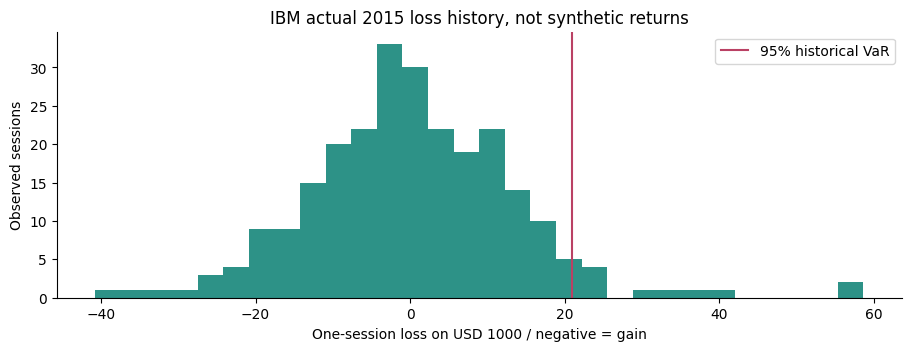

In [4]:
risk = risk_case(confidence=.95,notional=1000.,shots=SHOTS,seed=SEED)
table([dict(bin=i,probability=p,mean_loss=v,mean_tail_excess=e)
       for i,(p,v,e) in enumerate(zip(risk['probabilities'],risk['bin_values'],risk['excess_values']))])
print('Full-history classical reference:', {k:v for k,v in risk['raw_reference'].items() if k not in ['cdf','sorted_losses']})
print('Centroid-only reference:', {k:v for k,v in risk['centroid_binned_reference'].items() if k not in ['cdf','sorted_losses']})
table([dict(metric='Expected loss',historical=risk['raw_reference']['expected_loss'],native_mlae=risk['mean']['estimate'],interval=risk['mean']['confidence_interval']),
       dict(metric='CVaR / ES',historical=risk['raw_reference']['CVaR_expected_shortfall'],native_mlae=risk['cvar_estimate'],interval=risk['cvar_interval'])])
pl_risk_reference = pennylane_qmc(risk['probabilities'], risk['excess_values'], estimation_wires=5)
pl_risk_reference['cvar_estimate'] = risk['raw_reference']['VaR'] + pl_risk_reference['estimate']/(1-risk['confidence'])
pl_risk_reference['cvar_discrete_reference'] = risk['raw_reference']['VaR'] + pl_risk_reference['exact_discrete']/(1-risk['confidence'])
print('Actual PennyLane tail-excess phase grid:', {k:v for k,v in pl_risk_reference.items() if k != 'probabilities'})
table([dict(metric='CVaR / ES',historical=risk['raw_reference']['CVaR_expected_shortfall'],
            native_mlae=risk['cvar_estimate'],pennylane_qmc=pl_risk_reference['cvar_estimate'],
            pennylane_grid_error=pl_risk_reference['cvar_estimate']-pl_risk_reference['cvar_discrete_reference'])])
assert np.isclose(np.dot(risk['probabilities'],risk['bin_values']),np.mean(risk['losses']))
assert np.isclose(risk['raw_reference']['VaR']+np.dot(risk['probabilities'],risk['excess_values'])/.05,risk['raw_reference']['CVaR_expected_shortfall'])
assert np.isclose(pl_risk_reference['cvar_discrete_reference'],risk['raw_reference']['CVaR_expected_shortfall'])
fig, ax = plt.subplots(figsize=(9,3.4), layout='constrained')
ax.hist(risk['losses'],bins=30,color='#087f72',alpha=.85)
ax.axvline(risk['raw_reference']['VaR'],color='#ba4164',label='95% historical VaR')
ax.set(xlabel='One-session loss on USD 1000 / negative = gain',ylabel='Observed sessions',title='IBM actual 2015 loss history, not synthetic returns')
ax.legend(); plt.show()

<a id="hybrid"></a>
## 4. 可微分电路：混合波动模型研究

QMC 相位估计模板本身不可微；以下是**独立**的可训练模型，不能混为同一个可微算法。
用前两个已知日收益预测下一交易日绝对收益。最早 75% 为训练，末尾 25% 为验证，归一化仅从训练期估计。
2 比特 Native QNode 用 RY 编码、4 个旋转参数和 CNOT，测量 Z 期望；
经典线性头加 softplus 输出非负预测，PyTorch Adam 对量子参数和经典参数真实反向传播。
当前核心不支持本例多来源广播 backprop，因此逐条执行标量 QNode，**没有放宽资源上限**。
展示每轮损失、量子梯度范数、留出 MSE 与训练均值常数预测的 MSE。
若未优于常数基线也原样保留，不称为预测优势。

Training / validation dates: ['2015-01-07', '2015-10-01'] ['2015-10-02', '2015-12-31']


epoch,train_mse,quantum_gradient_norm
1,7.2909e-05,0.00640612
2,7.28068e-05,0.00352456
3,7.25956e-05,0.00139496
4,7.24284e-05,0.000830713
5,7.23227e-05,0.0032793
6,7.22654e-05,0.00594851
7,7.22187e-05,0.00869023
8,7.21541e-05,0.0113107
9,7.20716e-05,0.0136899
10,7.19846e-05,0.0157893


Real trained circuit parameters: [0.5436891472654173, -0.1902887424394269, -0.02339266552538731, -0.3258997203796482] | classical head: [-0.369248562806502, 0.6843136426398096]


validation_mse,constant_baseline_mse,beats_constant
9.70737e-05,9.45401e-05,False


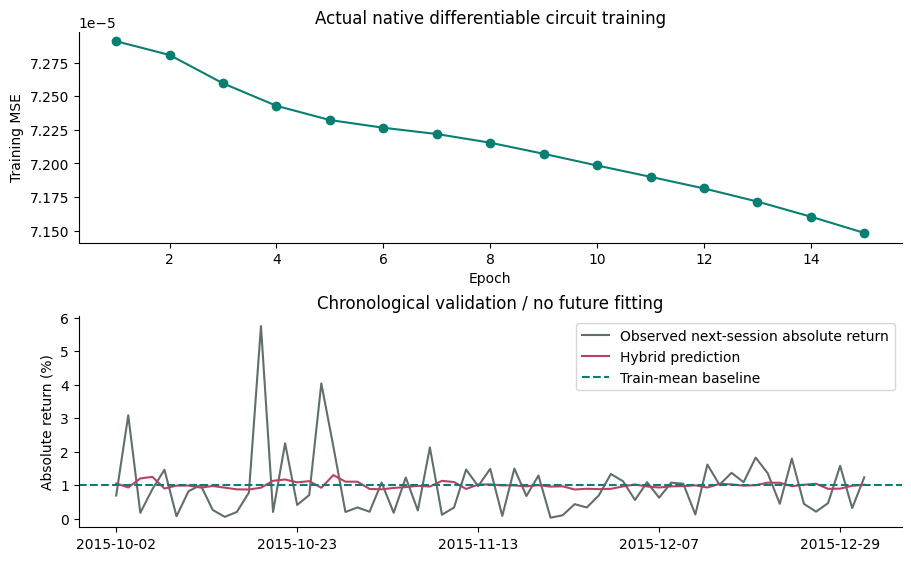

In [5]:
hybrid = hybrid_volatility_case(epochs=15,seed=SEED)
print('Training / validation dates:',hybrid['train_dates'],hybrid['validation_dates'])
table([dict(epoch=i+1,train_mse=mse,quantum_gradient_norm=g)
       for i,(mse,g) in enumerate(zip(hybrid['train_mse'],hybrid['circuit_gradient_norms']))])
print('Real trained circuit parameters:',hybrid['weights'],'| classical head:',hybrid['classical_head'])
table([dict(validation_mse=hybrid['validation_mse'],constant_baseline_mse=hybrid['baseline_mse'],
            beats_constant=hybrid['validation_mse'] < hybrid['baseline_mse'])])
fig, axes=plt.subplots(2,1,figsize=(9,5.5),layout='constrained')
axes[0].plot(range(1,16),hybrid['train_mse'],'o-',color='#087f72')
axes[0].set(xlabel='Epoch',ylabel='Training MSE',title='Actual native differentiable circuit training')
axes[1].plot(hybrid['dates'],np.array(hybrid['actual'])*100,label='Observed next-session absolute return',color='#626e6a')
axes[1].plot(hybrid['dates'],np.array(hybrid['predictions'])*100,label='Hybrid prediction',color='#ba4164')
axes[1].axhline(hybrid['target_scale']*100,color='#087f72',linestyle='--',label='Train-mean baseline')
axes[1].set(xticks=np.arange(0,len(hybrid['dates']),15),ylabel='Absolute return (%)',title='Chronological validation / no future fitting')
axes[1].legend(); plt.show()
qmc_evidence = dict(application='Native MLAE + PennyLane QMC + differentiable hybrid research',
                    pricing=clean(pricing), risk=clean(risk), hybrid=hybrid,
                    pennylane_reference=pl_reference, pennylane_risk_reference=pl_risk_reference,
                    gate_artifacts=gate_artifacts,
                    versions=versions, hardware_jobs=0)

## 运行边界与夸父迁移 / Limits & Quafu path

本次 **0 个云端/真机任务**，不消耗原金融批次额度、不改写其回执。
现有 D3 审计仍是 NO_NEW_SUBMISSION_RECOMMENDED；物理布局、位序和精度验收没有被本批模拟解除。
Native QAOA/MLAE 电路已分解为基础门并导出可检查的 QASM2，量子比特不超过 4；
QASM2 不能保存全局相位，因此导出显式记录所移除的顶层相位，只承诺终端测量概率，不能作为保相位受控子程序复用。
PennyLane 矩阵参考电路是 9 比特模拟，未承诺可在旧的 6 比特真机额度下运行。
未来接真机前需要独立核验 gate basis、耦合图、深度、布局、位序和额外任务预算；
深 Grover 电路可能受噪声限制，不能把成功序列化称为硬件可用，更不能声称量子优势。

本次只有小规模金融研究应用，并不表示已完成 Qiskit + PennyLane 全部核心函数融合或生产金融系统。

### 练习与解答骨架
改变预算或执行价，只使用训练期重新计算；比较目标、可行性、离散化和有限 shots 误差。
不要用留出期选择预算、股票、角度或训练超参数。

### 一手来源
- [D-Wave ExactCQMSolver：经典本地枚举](https://docs.dwavequantum.com/en/latest/ocean/api_ref_dimod/sampler_composites.html)
- [D-Wave 官方组合优化示例：概念参考，未复制源码](https://github.com/dwave-examples/portfolio-optimization)
- [PennyLane QuantumMonteCarlo：模板和模拟器限制](https://docs.pennylane.ai/en/stable/code/api/pennylane.QuantumMonteCarlo.html)
- [真实行情源：固定提交](https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv)
- [行情源仓库 MIT 许可](https://github.com/plotly/datasets/blob/master/LICENSE)
- [原有夸父 D3 契约审计](finance_quafu_d3_client_contract.html)

QuantumBridge · 所属 相干(北京)科技有限公司

In [6]:
print('EVIDENCE_JSON='+json.dumps(qmc_evidence, ensure_ascii=False, allow_nan=False))

EVIDENCE_JSON={"application": "Native MLAE + PennyLane QMC + differentiable hybrid research", "pricing": {"source": {"provider": "Plotly public datasets / stockdata.csv", "source_url": "https://github.com/plotly/datasets/blob/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv", "download_url": "https://raw.githubusercontent.com/plotly/datasets/0f7c47868a3393316098a8bf97d548e1ee23d22a/stockdata.csv", "source_commit": "0f7c47868a3393316098a8bf97d548e1ee23d22a", "sha256": "60bf505fec160ce05ba959382adee32ea6e53ce14fe22886db27c58fe1b0d26b", "retrieved_date_utc": "2026-11-01", "observations": ["2007-01-03", "2016-03-01"], "symbols": ["MSFT", "IBM", "SBUX", "AAPL", "GSPC"], "currency": "USD", "license_url": "https://github.com/plotly/datasets/blob/master/LICENSE", "license_file": "PLOTLY_LICENSE.txt", "license": "MIT as published by the source repository; original upstream data methodology is not documented", "price_basis": "Source-published historical price series. Split/dividend adjustm